In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.model_selection import train_test_split

# %matplotlib notebook
%matplotlib inline
import random
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)

    
from irl.utils import load_fast_demos

In [21]:
demos_new_km = pkl.load(open('../demos/fast_demos/20231106fastkmio.pkl','rb'))


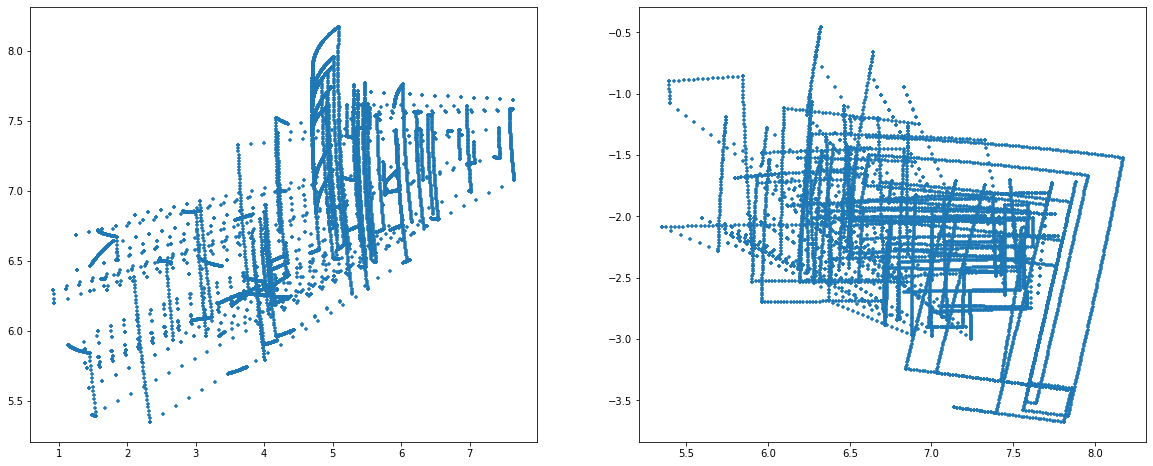

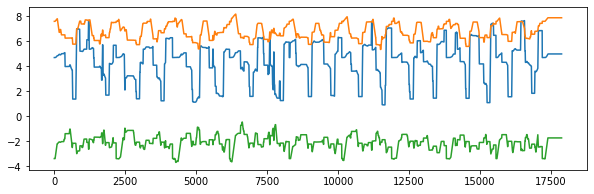

In [29]:
fig, axs = plt.subplots(1,2,figsize=(20,8))

axs[0].scatter(demos_new_km['obs'][10:,0], demos_new_km['obs'][10:,1],marker='+',s=10)
axs[1].scatter(demos_new_km['obs'][10:,1], demos_new_km['obs'][10:,2],marker='+',s=10)

fig2 = plt.figure(figsize=(10,3))

plt.plot(demos_new_km['obs'][10:,0])
plt.plot(demos_new_km['obs'][10:,1])
plt.plot(demos_new_km['obs'][10:,2])

In [2]:
demos_human = pkl.load(open('../demos/fast_demos/demo_an1.pkl','rb'))
demos_human_km_io = pkl.load(open('../demos/fast_demos/default_fast_demo.pkl','rb'))
demos_fw = pkl.load(open('../demos/fast_demos/demo_fw.pkl','rb'))

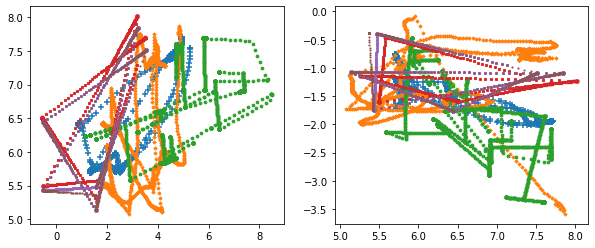

In [3]:
fig, axs = plt.subplots(1,2,figsize=(10,4))

axs[0].scatter(demos_human['obs'][10:,0], demos_human['obs'][10:,1],marker='+',s=30)
axs[0].scatter(demos_fw['obs'][10:,0], demos_fw['obs'][10:,1],marker='D',s=5)
axs[0].scatter(demos_human_km_io['obs'][10:,0], demos_human_km_io['obs'][10:,1],marker='.',s=30)

axs[0].scatter(demos_human['obs'][10:,7], demos_human['obs'][10:,8],marker='X',s=5)
axs[0].scatter(demos_fw['obs'][10:,7], demos_fw['obs'][10:,8],marker='X',s=5)
axs[0].scatter(demos_human_km_io['obs'][10:,7], demos_human_km_io['obs'][10:,8],marker='.',s=5)

axs[1].scatter(demos_human['obs'][10:,1], demos_human['obs'][10:,2],marker='+',s=30)
axs[1].scatter(demos_fw['obs'][10:,1], demos_fw['obs'][10:,2],marker='D',s=5)
axs[1].scatter(demos_human_km_io['obs'][10:,1], demos_human_km_io['obs'][10:,2],marker='.',s=30)

axs[1].scatter(demos_human['obs'][10:,8], demos_human['obs'][10:,9],marker='X',s=5)
axs[1].scatter(demos_fw['obs'][10:,8], demos_fw['obs'][10:,9],marker='X',s=5)
axs[1].scatter(demos_human_km_io['obs'][10:,8], demos_human_km_io['obs'][10:,9],marker='.',s=5)


### Fit GP on 3D position data and measure distances between experts

In [5]:
pos_data = demos_human['obs'][10:,:3]
pos_data.shape

(863, 3)

In [11]:
nv = 100  # Number of points in each direction
xv = np.linspace(-5.,5.,nv)  # x-vector
yv = np.linspace(-5.,5.,nv)  # y-vector
x, y = np.meshgrid(xv, yv)  # x and y are (nv, nv) matrices
z = (x-3.)**2. + 2.*x*y + (2.*y+3.)**2. - 3.

noise_level = 5.
z_noisy = z + np.random.normal(size=x.shape) * noise_level

X = np.column_stack((x.reshape(-1), y.reshape(-1)))
Z = z_noisy.reshape(-1,1)

guess_l = (2., 1.)  # In general, x and y have different scales
bounds_l = ((1e-1,100.),) * 2  # Same bounds for x and y
guess_n = 1.  # Amount of noise
bounds_n = (1e-20, 10.) # Bounds for noise
kernel = (  # Kernel objects can simply be summed using +
    RBF(length_scale=guess_l, length_scale_bounds=bounds_l)
    + WhiteKernel(noise_level=guess_n, noise_level_bounds=bounds_n)
)

In [12]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Z, test_size=0.95)
print(X_train.shape, Y_train.shape)

(500, 2) (500, 1)


In [13]:
gpr = GaussianProcessRegressor(kernel, normalize_y=True )
gpr.fit(X_train, Y_train)

GaussianProcessRegressor(kernel=RBF(length_scale=[2, 1]) + WhiteKernel(noise_level=1),
                         normalize_y=True)

### plot results

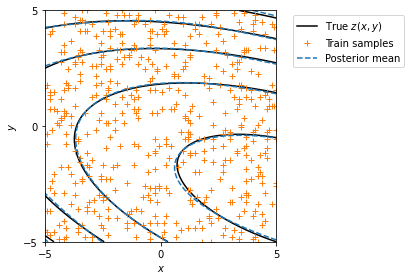

In [16]:
Zfit, Zstd = gpr.predict(X, return_std=True)
zstd = Zstd.reshape(x.shape)
zfit = Zfit.reshape(x.shape)

# Set up figure
fig, ax = plt.subplots(figsize=(6., 4.))
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_xlim((-5,5))
ax.set_ylim((-5,5))
ax.set_aspect('equal')
ax.set_xticks((-5,0,5))
ax.set_yticks((-5,0,5))
ax.grid(False)

# Do the plotting
lev = np.linspace(0.,250.,6)
ax.contour(x,y,z,lev,colors='k')  # Truth
ax.plot(*X_train.T,'+',color="C1")  # Training samples
ax.contour(x, y,zfit, lev, colors='C0', linestyles='dashed')  # Posterior mean

# Legend
truth_line = mlines.Line2D([], [], color='black', label='True $z(x,y)$')
sample_line = mlines.Line2D([], [], color='C1', marker="+", linestyle="none", label='Train samples')
mean_line = mlines.Line2D([], [], color='C0', linestyle="--", label='Posterior mean')
ax.legend(handles=[truth_line, sample_line, mean_line],bbox_to_anchor=(1.05, 1), loc="upper left")

# Write out
plt.tight_layout()


In [2]:
import gymnasium as gym
import torch
import argparse
from argparse import Namespace

gym.envs.register(
     id='FASTIC-v0',
     entry_point='envs.env_fast:FASTRL',
     max_episode_steps=10000,
)

SEED = 42
PORT_OFFSET = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

d = {'executable_name': '../envs/fast/fast_ic_ca.app',
     'seed': SEED,
     'run_name': 'runs/test_determinism'}
args = Namespace(**d)

test_env = gym.make('FASTIC-v0', args=args, no_graphics=False, time_scale=1, port_offset=PORT_OFFSET+4)


/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/torch/utils/tensorboard/__init__.py:4: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if not hasattr(tensorboard, '__version__') or LooseVersion(tensorboard.__version__) < LooseVersion('1.15'):
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/torch/utils/tensorboard/__init__.py:4: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if not hasattr(tensorboard, '__version__') or LooseVersion(tensorboard.__version__) < LooseVersion('1.15'):
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/mlagents/torch_utils/torch.py:21: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  assert torch_pkg is not None and LooseVersion(torch_pkg.version) >= LooseVersion(
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/mlagents/torch_utils/torch.py:21: DeprecationWarning: dis

[INFO] Connected to Unity environment with package version 2.0.1 and communication version 1.5.0


/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/mlagents_envs/environment.py:94: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  unity_communicator_version = StrictVersion(unity_com_ver)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/mlagents_envs/environment.py:95: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  api_version = StrictVersion(python_api_version)
INFO:mlagents_envs.environment:Connected to Unity environment with package version 2.0.1 and communication version 1.5.0


[INFO] Connected new brain: ImageCentering?team=0


INFO:mlagents_envs.environment:Connected new brain: ImageCentering?team=0


[WARNING] Deleting TensorBoard data events.out.tfevents.1698330879.Ivans-MBP-3.85943.0 that was left over from a previous run.


[WARNING] The environment contains multiple observations. You must define allow_multiple_obs=True to receive them all. Otherwise, only the first visual observation (or vector observation ifthere are no visual observations) will be provided in the observation.


In [3]:
test_env.reset()

(array([ 4.7020340e+00,  7.5970941e+00, -3.3749537e+00,  3.0384363e-08,
         7.0710695e-01,  7.0710665e-01, -3.0966440e-08,  2.8008573e+00,
         2.5260882e+00, -9.6254516e-01,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  1.0000000e+00, -6.1098933e-01,  5.6662416e-01,
         5.5283737e-01,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  5.0000000e-01,
         5.0000000e-01, -5.0000000e-01, -5.0000000e-01, -9.9994206e-01,
         2.8602779e-05, -1.0791421e-02,  1.8736124e-03,  9.8526847e-01,
        -1.7100462e-01,  1.9011767e+00,  5.0710058e+00, -2.4124086e+00,
        -6.0201287e-03,  5.6660688e-01,  5.5936623e-01, -7.8077652e-02,
         3.4985316e+00,  7.2440133e+00,  5.6920567e+00,  8.0449696e+00,
         5.4480053e+01], dtype=float32),
 {})

In [4]:
o_l = []
for i in range(10000):
    action = test_env.action_space.sample()
    o,r,t,tr,i = test_env.step(action)
    o_l.append(o)

np.sum(o_l)

139016.25

In [4]:
o_l = []
for i in range(1000):
    action = test_env.action_space.sample()
    o,r,t,tr,i = test_env.step(action)
    o_l.append(o)

np.sum(o_l)

139016.23

In [18]:
NTRAJ = 10
TRAJLEN = 100
DIM = 5

# random walk gaussian process
rw_data = []
for i in range(NTRAJ):
    x0 = np.random.randn(DIM)
    tr = [x0]
    for j in range(TRAJLEN-1):
        x = tr[-1]
        tr.append(x + np.random.randn(DIM))
    rw_data.append(tr)
    
rw_data = np.reshape(np.array(rw_data), (-1,DIM))      
X_train, X_test, Y_train, Y_test = train_test_split(rw_data, rw_data[:,0], test_size=0.95)


In [19]:
kernel = (  # Kernel objects can simply be summed using +
    RBF(length_scale=np.ones(DIM))
    + WhiteKernel(noise_level=1.)
)

In [20]:
gpr = GaussianProcessRegressor(kernel, normalize_y=True )
gpr.fit(X_train, Y_train)

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/iov/.miniforge3

GaussianProcessRegressor(kernel=RBF(length_scale=[1, 1, 1, 1, 1]) + WhiteKernel(noise_level=1),
                         normalize_y=True)